# Task 3: Player Monthly Spending Prediction (Upgraded Leak-Free Pipeline)
## CPE342 Machine Learning - Team ML009

### สรุปสถาปัตยกรรมและการปรับปรุงโมเดลแบบไร้ Data Leakage
- เป้าหมายคือการทำนายยอดใช้จ่ายรายเดือนของผู้เล่น `spending_30d` ในหน่วยบาท โดยวัดผลด้วยค่า Normalized Mean Absolute Error หรือ NMAE ซึ่งมีค่าสูงสุดคือ 1.0
  $$\text{NMAE} = \frac{1}{1 + \frac{\sum_{i=1}^{N} |y_i - \hat{y}_i|}{\sum_{i=1}^{N} y_i}}$$
- การปรับปรุงหลัก 4 ส่วนเพื่อเพิ่มความแม่นยำบนข้อมูลที่ไม่เคยเห็นมาก่อนโดยไม่เกิด Overfitting
  1. การกู้คืนค่าว่างด้วยสมการความสัมพันธ์เชิงพีชคณิตแม่นยำ 4 สมการก่อนการเติมค่าว่าง ได้แก่ `historical_spending = total_transactions * avg_transaction_value`, `purchases_on_discount = total_transactions * discount_rate_used`, `is_premium_member = (vip_status >= 3)` และ `prev_month_spending = 0.35 * historical_spending` ร่วมกับการใช้โมเดล GBDT ที่เทรนเฉพาะในแต่ละ Training Fold เพื่อกู้คืนค่า `segment` และฟีเจอร์สำคัญแทนการถมด้วยค่ามัธยฐานรวมที่ทำให้ข้อมูลผู้เล่นกลุ่ม Whale เพี้ยน
  2. การสร้างฟีเจอร์ตามโครงสร้างการกระจายตัวแบบผลคูณของฤดูกาลและระดับสมาชิก ร่วมกับฟีเจอร์พฤติกรรม RFM และความผูกพันของผู้เล่น
  3. การเทรนโมเดลสองขั้นตอนบน 5-Fold Stratified Cross-Validation เดียวกันแบบ Out-Of-Fold แท้ 100 เปอร์เซ็นต์ โดย Stage 1 ใช้การผสมโมเดล LightGBM, XGBoost และ CatBoost ทำนายความน่าจะเป็นในการใช้จ่าย $p_i = P(Y_i > 0 \mid X_i)$ และ Stage 2 เปลี่ยนจากการทำนายค่าเฉลี่ยด้วย Tweedie มาเป็นการทำนายค่ามัธยฐานด้วย L1 Loss บนสเกลอัตราส่วนลอการิทึม $\log(Y_i / \text{historical\_spending}_i)$ และ $\log(Y_i / \text{prev\_month\_spending}_i)$ ซึ่งลดความคลาดเคลื่อนของผู้มียอดใช้จ่ายจาก 3,679.32 บาท เหลือ 3,326.02 บาท
  4. การรวมผลลัพธ์ด้วยสมการ Bayes-Optimal Zero-Inflated L1 Quantile Mapping $\hat{y}_i = \alpha \cdot \hat{m}_i \cdot Q_U\!\left(\frac{p_i - \tau}{p_i}\right)$ สำหรับผู้เล่นที่มี $p_i > \tau$ และตรวจสอบความเสถียรด้วย Nested 5-Fold Cross-Validation


## 1. การตั้งค่าสภาพแวดล้อมและการโหลดข้อมูล
กำหนดค่า Random Seed คงที่ โหลดไลบรารีหลัก และตรวจสอบขนาดของชุดข้อมูล `train.csv` และ `test.csv`


In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, mean_absolute_error

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor

SEED = 42
N_SPLITS = 5
EPSILON = 1e-6
np.random.seed(SEED)

CANDIDATE_DIRS = ["../data/task3", "data/task3", "."]
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(os.path.join(d, "train.csv"))), "../data/task3")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

ID_COL = "id" if "id" in test_df.columns else test_df.columns[0]
TARGET_COL = "spending_30d"
raw_features = [c for c in train_df.columns if c not in ["id", "player_id", TARGET_COL]]

y_all = train_df[TARGET_COL].values.astype(np.float64)
is_spender = (y_all > 0).astype(int)

print(f"Data Directory : {os.path.abspath(DATA_DIR)}")
print(f"Train Shape    : {train_df.shape} | Test Shape : {test_df.shape}")
print(f"Non-Spenders   : {(y_all == 0).sum():,} ({(y_all == 0).mean()*100:.2f}%) | Active Spenders : {(y_all > 0).sum():,} ({(y_all > 0).mean()*100:.2f}%)")


Data Directory : c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\data\task3
Train Shape    : (104000, 34) | Test Shape : (25889, 33)
Non-Spenders   : 50,049 (48.12%) | Active Spenders : 53,951 (51.88%)


## 2. ฟังก์ชันคำนวณ NMAE และการกู้คืนค่าว่างเชิงพีชคณิตแบบแยกตาม Fold
กู้คืนค่าว่างจากความสัมพันธ์เชิงพีชคณิตที่แม่นยำ 100 เปอร์เซ็นต์ในระดับแถวข้อมูล แล้วเทรนโมเดลเติมค่าว่างเฉพาะบนชุด `df_tr_raw` ของแต่ละ Fold เท่านั้น เพื่อป้องกัน Data Leakage จาก Validation Fold และ Test Set


In [2]:
def calculate_nmae(y_true, y_pred) -> float:
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.clip(np.asarray(y_pred, dtype=np.float64), 0.0, None)
    y_sum = np.sum(y_true)
    if y_sum == 0:
        return 0.0
    return float(1.0 / (1.0 + (np.sum(np.abs(y_true - y_pred)) / y_sum)))

def optimize_simplex_weights(oof_list, y_true, loss_fn) -> np.ndarray:
    n_m = len(oof_list)
    init_w = np.ones(n_m) / n_m
    bounds = [(0.0, 1.0)] * n_m
    cons = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
    res = minimize(
        lambda w: loss_fn(y_true, sum(w[i] * oof_list[i] for i in range(n_m))),
        init_w, method="SLSQP", bounds=bounds, constraints=cons
    )
    return res.x / np.sum(res.x)

def apply_exact_algebraic_recovery(df):
    d = df.copy()
    for c in ["historical_spending", "prev_month_spending", "segment", "vip_status", "event_participation_rate"]:
        d[f"{c}_isna"] = d[c].isna().astype(float)

    # Identity 1: purchases_on_discount == total_transactions * discount_rate_used
    m_tot_from_disc = d["total_transactions"].isna() & d["purchases_on_discount"].notna() & (d["discount_rate_used"] > 0)
    d.loc[m_tot_from_disc, "total_transactions"] = np.round(d.loc[m_tot_from_disc, "purchases_on_discount"] / d.loc[m_tot_from_disc, "discount_rate_used"])

    # Identity 2: historical_spending == total_transactions * avg_transaction_value
    m_hist = d["historical_spending"].isna() & d["total_transactions"].notna() & d["avg_transaction_value"].notna()
    d.loc[m_hist, "historical_spending"] = d.loc[m_hist, "total_transactions"] * d.loc[m_hist, "avg_transaction_value"]

    m_tot = d["total_transactions"].isna() & d["historical_spending"].notna() & (d["avg_transaction_value"] > 0)
    d.loc[m_tot, "total_transactions"] = np.round(d.loc[m_tot, "historical_spending"] / d.loc[m_tot, "avg_transaction_value"])

    m_avg = d["avg_transaction_value"].isna() & d["historical_spending"].notna() & (d["total_transactions"] > 0)
    d.loc[m_avg, "avg_transaction_value"] = d.loc[m_avg, "historical_spending"] / d.loc[m_avg, "total_transactions"]

    m_hist2 = d["historical_spending"].isna() & d["total_transactions"].notna() & d["avg_transaction_value"].notna()
    d.loc[m_hist2, "historical_spending"] = d.loc[m_hist2, "total_transactions"] * d.loc[m_hist2, "avg_transaction_value"]

    m_disc = d["purchases_on_discount"].isna() & d["total_transactions"].notna() & d["discount_rate_used"].notna()
    d.loc[m_disc, "purchases_on_discount"] = np.round(d.loc[m_disc, "total_transactions"] * d.loc[m_disc, "discount_rate_used"])

    m_drate = d["discount_rate_used"].isna() & d["purchases_on_discount"].notna() & (d["total_transactions"] > 0)
    d.loc[m_drate, "discount_rate_used"] = d.loc[m_drate, "purchases_on_discount"] / d.loc[m_drate, "total_transactions"]

    # Identity 3: is_premium_member == (vip_status >= 3)
    m_prem = d["is_premium_member"].isna() & d["vip_status"].notna()
    d.loc[m_prem, "is_premium_member"] = (d.loc[m_prem, "vip_status"] >= 3.0).astype(float)

    # Identity 4: prev_month_spending == 0.3500 * historical_spending
    m_hist_from_prev = d["historical_spending"].isna() & d["prev_month_spending"].notna()
    d.loc[m_hist_from_prev, "historical_spending"] = d.loc[m_hist_from_prev, "prev_month_spending"] / 0.3500

    m_prev_from_hist = d["prev_month_spending"].isna() & d["historical_spending"].notna()
    d.loc[m_prev_from_hist, "prev_month_spending"] = d.loc[m_prev_from_hist, "historical_spending"] * 0.3500
    return d

def build_fold_features(df_tr_raw, df_va_raw, df_te_raw):
    d_tr = apply_exact_algebraic_recovery(df_tr_raw)
    d_va = apply_exact_algebraic_recovery(df_va_raw)
    d_te = apply_exact_algebraic_recovery(df_te_raw)

    imp_predictors = [
        "historical_spending", "prev_month_spending", "event_participation_rate",
        "vip_status", "is_premium_member", "total_transactions", "avg_transaction_value",
        "purchases_on_discount", "owns_limited_edition", "tournament_participation"
    ]

    seg_valid_tr = d_tr["segment"].notna()
    m_seg = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1, n_jobs=-1)
    m_seg.fit(d_tr.loc[seg_valid_tr, imp_predictors], d_tr.loc[seg_valid_tr, "segment"].astype(int))
    for d in [d_tr, d_va, d_te]:
        na_seg = d["segment"].isna()
        if na_seg.sum() > 0:
            d.loc[na_seg, "segment"] = m_seg.predict(d.loc[na_seg, imp_predictors]).astype(float)
        seg_probs = m_seg.predict_proba(d[imp_predictors])
        for s_i in range(4):
            d[f"seg_prob_{s_i}"] = seg_probs[:, s_i]

    for target_c in ["vip_status", "event_participation_rate", "historical_spending", "prev_month_spending",
                     "days_since_last_purchase", "purchase_frequency", "games_played", "cross_game_activity"]:
        preds_c = [c for c in raw_features if c != target_c]
        valid_tr = d_tr[target_c].notna()
        m_c = lgb.LGBMRegressor(objective="mae", n_estimators=120, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1, n_jobs=-1)
        m_c.fit(d_tr.loc[valid_tr, preds_c], d_tr.loc[valid_tr, target_c])
        for d in [d_tr, d_va, d_te]:
            na_c = d[target_c].isna()
            if na_c.sum() > 0:
                pred_vals = m_c.predict(d.loc[na_c, preds_c])
                if target_c == "vip_status":
                    pred_vals = np.clip(np.round(pred_vals), 0, 5)
                    prem_known = d.loc[na_c, "is_premium_member"].notna()
                    is_p1 = d.loc[na_c, "is_premium_member"] == 1.0
                    is_p0 = d.loc[na_c, "is_premium_member"] == 0.0
                    pred_vals = np.where(prem_known & is_p1, np.clip(pred_vals, 3, 5), pred_vals)
                    pred_vals = np.where(prem_known & is_p0, np.clip(pred_vals, 0, 2), pred_vals)
                d.loc[na_c, target_c] = pred_vals

    for d in [d_tr, d_va, d_te]:
        m_p = d["is_premium_member"].isna() & d["vip_status"].notna()
        d.loc[m_p, "is_premium_member"] = (d.loc[m_p, "vip_status"] >= 3.0).astype(float)

        d["spend_trend"] = d["prev_month_spending"] / (d["historical_spending"] + EPSILON)
        d["spend_per_day"] = d["historical_spending"] / (d["account_age_days"] + 1.0)
        d["tx_per_day"] = d["total_transactions"] / (d["account_age_days"] + 1.0)
        d["playtime_per_day"] = d["total_playtime_hours"] / (d["account_age_days"] + 1.0)
        d["discount_tx_ratio"] = d["purchases_on_discount"] / (d["total_transactions"] + 1.0)
        d["social_per_friend"] = d["social_interactions"] / (d["friend_count"] + 1.0)
        d["login_recency_ratio"] = d["days_since_last_login"] / (d["account_age_days"] + 1.0)
        d["purchase_recency_ratio"] = d["days_since_last_purchase"] / (d["account_age_days"] + 1.0)
        d["session_intensity"] = d["avg_session_length"] * d["sessions_per_week"]
        d["value_per_hour"] = d["historical_spending"] / (d["total_playtime_hours"] + 1.0)

        d["is_holiday_season"] = d["seasonal_spending_pattern"].isin([0.0, 11.0]).astype(float)
        d["is_summer_season"] = d["seasonal_spending_pattern"].isin([5.0, 6.0]).astype(float)
        d["season_mult"] = 1.0 + 0.25 * d["is_holiday_season"] + 0.15 * d["is_summer_season"]
        d["vip_mult"] = (1.0 + 0.12 * d["vip_status"].fillna(1.0)) * np.where(d["is_premium_member"].fillna(0.0) == 1.0, 1.18, 1.0)
        d["seg_mult"] = d["segment"].map({0.0: 0.40, 1.0: 0.63, 2.0: 0.76, 3.0: 1.56}).fillna(0.75)
        d["expected_base_spend"] = d["historical_spending"] * d["seg_mult"] * d["season_mult"] * (d["vip_mult"] / 1.25)
        d["clean_base_spend"] = 0.5 * d["historical_spending"] + 0.5 * (d["prev_month_spending"] / 0.3500)
        d["log_hist"] = np.log1p(np.clip(d["historical_spending"], 0, None))
        d["log_prev"] = np.log1p(np.clip(d["prev_month_spending"], 0, None))
        d["log_avg_tx"] = np.log1p(np.clip(d["avg_transaction_value"], 0, None))

    for c in d_tr.columns:
        med = d_tr[c].median()
        d_tr[c] = d_tr[c].fillna(med)
        d_va[c] = d_va[c].fillna(med)
        d_te[c] = d_te[c].fillna(med)
    return d_tr, d_va, d_te

check_alg = apply_exact_algebraic_recovery(train_df[raw_features])
print(f"Missing historical_spending in raw train : {train_df['historical_spending'].isna().sum():,} -> After Exact Algebraic Recovery : {check_alg['historical_spending'].isna().sum():,}")
print(f"Missing prev_month_spending in raw train : {train_df['prev_month_spending'].isna().sum():,} -> After Exact Algebraic Recovery : {check_alg['prev_month_spending'].isna().sum():,}")


Missing historical_spending in raw train : 6,035 -> After Exact Algebraic Recovery : 40
Missing prev_month_spending in raw train : 6,015 -> After Exact Algebraic Recovery : 40


## 3. การเทรนโมเดล Stage 1 และ Stage 2 บน 5-Fold Stratified Cross-Validation เดียวกัน
ทั้ง Stage 1 และ Stage 2 ใช้การแบ่ง Fold ชุดเดียวกัน เพื่อให้ค่าทำนาย Out-Of-Fold ของผู้เล่นทั้ง 104,000 คนเป็นค่าทำนายจากโมเดลที่ไม่เคยเห็นข้อมูลแถวนั้นมาก่อน 100 เปอร์เซ็นต์


In [3]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
n_train = len(train_df)
n_test = len(test_df)

oof_s1_lgb, test_s1_lgb = np.zeros(n_train), np.zeros(n_test)
oof_s1_xgb, test_s1_xgb = np.zeros(n_train), np.zeros(n_test)
oof_s1_cat, test_s1_cat = np.zeros(n_train), np.zeros(n_test)

N_S2_MODELS = 7
s2_names = [
    "CatBoost_log(y/hist)",
    "CatBoost_log(y/prev)",
    "CatBoost_log(y/base)",
    "XGBoost_log(y/hist)",
    "XGBoost_log(y/prev)",
    "LightGBM_log(y/hist)",
    "LightGBM_weighted(y/hist)"
]
oof_s2_models = [np.zeros(n_train) for _ in range(N_S2_MODELS)]
test_s2_models = [np.zeros(n_test) for _ in range(N_S2_MODELS)]

print("Training 5-Fold Leak-Free Stage 1 Classifiers & Stage 2 Log-Ratio L1 Regressors...")
for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, is_spender)):
    f_t0 = time.time()
    X_tr, X_va, X_te = build_fold_features(
        train_df[raw_features].iloc[tr_idx],
        train_df[raw_features].iloc[va_idx],
        test_df[raw_features]
    )
    y_tr, y_va = y_all[tr_idx], y_all[va_idx]
    sp_tr, sp_va = is_spender[tr_idx] == 1, is_spender[va_idx] == 1

    # Stage 1: Binary Classification
    clf_lgb = lgb.LGBMClassifier(
        n_estimators=1000, learning_rate=0.025, num_leaves=23, max_depth=5,
        min_child_samples=60, subsample=0.8, colsample_bytree=0.8, reg_alpha=0.5, reg_lambda=2.0,
        random_state=SEED + fold, n_jobs=-1, verbose=-1
    )
    clf_lgb.fit(X_tr, is_spender[tr_idx], eval_set=[(X_va, is_spender[va_idx])], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_s1_lgb[va_idx] = clf_lgb.predict_proba(X_va)[:, 1]
    test_s1_lgb += clf_lgb.predict_proba(X_te)[:, 1] / N_SPLITS

    clf_xgb = xgb.XGBClassifier(
        n_estimators=1000, learning_rate=0.025, max_depth=5, min_child_weight=50,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.5, reg_lambda=2.0,
        eval_metric="logloss", early_stopping_rounds=50, random_state=SEED + fold, n_jobs=-1, tree_method="hist"
    )
    clf_xgb.fit(X_tr, is_spender[tr_idx], eval_set=[(X_va, is_spender[va_idx])], verbose=False)
    oof_s1_xgb[va_idx] = clf_xgb.predict_proba(X_va)[:, 1]
    test_s1_xgb += clf_xgb.predict_proba(X_te)[:, 1] / N_SPLITS

    clf_cat = CatBoostClassifier(
        iterations=1200, learning_rate=0.035, depth=6, l2_leaf_reg=5.0,
        eval_metric="Logloss", random_seed=SEED + fold, thread_count=-1, verbose=0
    )
    clf_cat.fit(X_tr, is_spender[tr_idx], eval_set=(X_va, is_spender[va_idx]), early_stopping_rounds=50, verbose=False)
    oof_s1_cat[va_idx] = clf_cat.predict_proba(X_va)[:, 1]
    test_s1_cat += clf_cat.predict_proba(X_te)[:, 1] / N_SPLITS

    # Stage 2: Conditional Multiplicative Log-Ratio L1 Regressors
    hist_tr = np.clip(X_tr["historical_spending"].values[sp_tr], 1e-2, None)
    hist_va = np.clip(X_va["historical_spending"].values, 1e-2, None)
    hist_te = np.clip(X_te["historical_spending"].values, 1e-2, None)

    prev_tr = np.clip(X_tr["prev_month_spending"].values[sp_tr], 1e-2, None)
    prev_va = np.clip(X_va["prev_month_spending"].values, 1e-2, None)
    prev_te = np.clip(X_te["prev_month_spending"].values, 1e-2, None)

    base_tr = np.clip(X_tr["clean_base_spend"].values[sp_tr], 1e-2, None)
    base_va = np.clip(X_va["clean_base_spend"].values, 1e-2, None)
    base_te = np.clip(X_te["clean_base_spend"].values, 1e-2, None)

    t_lrh_tr = np.log(np.clip(y_tr[sp_tr] / hist_tr, 1e-4, None))
    t_lrh_va = np.log(np.clip(y_va[sp_va] / hist_va[sp_va], 1e-4, None))

    t_lrp_tr = np.log(np.clip(y_tr[sp_tr] / prev_tr, 1e-4, None))
    t_lrp_va = np.log(np.clip(y_va[sp_va] / prev_va[sp_va], 1e-4, None))

    t_lrb_tr = np.log(np.clip(y_tr[sp_tr] / base_tr, 1e-4, None))
    t_lrb_va = np.log(np.clip(y_va[sp_va] / base_va[sp_va], 1e-4, None))

    m0 = CatBoostRegressor(loss_function="MAE", eval_metric="MAE", iterations=1600, learning_rate=0.035, depth=6, l2_leaf_reg=5.0, random_seed=SEED + fold, thread_count=-1, verbose=0)
    m0.fit(X_tr[sp_tr], t_lrh_tr, eval_set=(X_va[sp_va], t_lrh_va), early_stopping_rounds=70, verbose=False)
    oof_s2_models[0][va_idx] = np.clip(np.exp(m0.predict(X_va)) * hist_va, 0, 300000)
    test_s2_models[0] += np.clip(np.exp(m0.predict(X_te)) * hist_te, 0, 300000) / N_SPLITS

    m1 = CatBoostRegressor(loss_function="MAE", eval_metric="MAE", iterations=1600, learning_rate=0.035, depth=6, l2_leaf_reg=5.0, random_seed=SEED + 10 + fold, thread_count=-1, verbose=0)
    m1.fit(X_tr[sp_tr], t_lrp_tr, eval_set=(X_va[sp_va], t_lrp_va), early_stopping_rounds=70, verbose=False)
    oof_s2_models[1][va_idx] = np.clip(np.exp(m1.predict(X_va)) * prev_va, 0, 300000)
    test_s2_models[1] += np.clip(np.exp(m1.predict(X_te)) * prev_te, 0, 300000) / N_SPLITS

    m2 = CatBoostRegressor(loss_function="MAE", eval_metric="MAE", iterations=1600, learning_rate=0.035, depth=6, l2_leaf_reg=5.0, random_seed=SEED + 20 + fold, thread_count=-1, verbose=0)
    m2.fit(X_tr[sp_tr], t_lrb_tr, eval_set=(X_va[sp_va], t_lrb_va), early_stopping_rounds=70, verbose=False)
    oof_s2_models[2][va_idx] = np.clip(np.exp(m2.predict(X_va)) * base_va, 0, 300000)
    test_s2_models[2] += np.clip(np.exp(m2.predict(X_te)) * base_te, 0, 300000) / N_SPLITS

    m3 = xgb.XGBRegressor(objective="reg:absoluteerror", eval_metric="mae", n_estimators=1400, learning_rate=0.025, max_depth=5, min_child_weight=50, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, early_stopping_rounds=60, random_state=SEED + fold, n_jobs=-1, tree_method="hist")
    m3.fit(X_tr[sp_tr], t_lrh_tr, eval_set=[(X_va[sp_va], t_lrh_va)], verbose=False)
    oof_s2_models[3][va_idx] = np.clip(np.exp(m3.predict(X_va)) * hist_va, 0, 300000)
    test_s2_models[3] += np.clip(np.exp(m3.predict(X_te)) * hist_te, 0, 300000) / N_SPLITS

    m4 = xgb.XGBRegressor(objective="reg:absoluteerror", eval_metric="mae", n_estimators=1400, learning_rate=0.025, max_depth=5, min_child_weight=50, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, early_stopping_rounds=60, random_state=SEED + 10 + fold, n_jobs=-1, tree_method="hist")
    m4.fit(X_tr[sp_tr], t_lrp_tr, eval_set=[(X_va[sp_va], t_lrp_va)], verbose=False)
    oof_s2_models[4][va_idx] = np.clip(np.exp(m4.predict(X_va)) * prev_va, 0, 300000)
    test_s2_models[4] += np.clip(np.exp(m4.predict(X_te)) * prev_te, 0, 300000) / N_SPLITS

    m5 = lgb.LGBMRegressor(objective="mae", n_estimators=1400, learning_rate=0.025, num_leaves=23, max_depth=5, min_child_samples=60, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, random_state=SEED + fold, n_jobs=-1, verbose=-1)
    m5.fit(X_tr[sp_tr], t_lrh_tr, eval_set=[(X_va[sp_va], t_lrh_va)], callbacks=[lgb.early_stopping(60, verbose=False)])
    oof_s2_models[5][va_idx] = np.clip(np.exp(m5.predict(X_va)) * hist_va, 0, 300000)
    test_s2_models[5] += np.clip(np.exp(m5.predict(X_te)) * hist_te, 0, 300000) / N_SPLITS

    m6 = lgb.LGBMRegressor(objective="mae", n_estimators=1200, learning_rate=0.025, num_leaves=15, max_depth=5, min_child_samples=120, subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, random_state=SEED + fold, n_jobs=-1, verbose=-1)
    m6.fit(X_tr[sp_tr], y_tr[sp_tr] / hist_tr, sample_weight=hist_tr, eval_set=[(X_va[sp_va], y_va[sp_va] / hist_va[sp_va])], eval_sample_weight=[hist_va[sp_va]], callbacks=[lgb.early_stopping(60, verbose=False)])
    oof_s2_models[6][va_idx] = np.clip(m6.predict(X_va) * hist_va, 0, 300000)
    test_s2_models[6] += np.clip(m6.predict(X_te) * hist_te, 0, 300000) / N_SPLITS

    fold_p = (oof_s1_lgb[va_idx] + oof_s1_xgb[va_idx] + oof_s1_cat[va_idx]) / 3.0
    fold_y2 = np.mean([oof_s2_models[m_i][va_idx] for m_i in range(N_S2_MODELS)], axis=0)
    print(f"  Fold {fold+1}/5 ({time.time()-f_t0:.1f}s) | Stage 1 AUC: {roc_auc_score(sp_va, fold_p):.5f} | Stage 2 Spender MAE: {mean_absolute_error(y_va[sp_va], fold_y2[sp_va]):.2f} THB")


Training 5-Fold Leak-Free Stage 1 Classifiers & Stage 2 Log-Ratio L1 Regressors...
  Fold 1/5 (98.2s) | Stage 1 AUC: 0.78146 | Stage 2 Spender MAE: 3267.52 THB
  Fold 2/5 (89.1s) | Stage 1 AUC: 0.78602 | Stage 2 Spender MAE: 3302.66 THB
  Fold 3/5 (89.4s) | Stage 1 AUC: 0.78792 | Stage 2 Spender MAE: 3406.82 THB
  Fold 4/5 (86.6s) | Stage 1 AUC: 0.78718 | Stage 2 Spender MAE: 3367.16 THB
  Fold 5/5 (83.5s) | Stage 1 AUC: 0.78280 | Stage 2 Spender MAE: 3303.47 THB


## 4. การผสมโมเดลด้วย Convex Simplex Optimization และสมการ Bayes-Optimal Zero-Inflated L1 Quantile
คำนวณน้ำหนักการผสมโมเดลบนชุด Out-Of-Fold และใช้สมการควอนไทล์ของฟังก์ชันความสูญเสียแบบ L1 สำหรับการแจกแจงที่มีศูนย์ปนอยู่ในสัดส่วนสูง พร้อมตรวจสอบผลด้วย Nested 5-Fold Cross-Validation


In [4]:
w_s1 = optimize_simplex_weights([oof_s1_lgb, oof_s1_xgb, oof_s1_cat], is_spender, log_loss)
oof_s1_prob = w_s1[0] * oof_s1_lgb + w_s1[1] * oof_s1_xgb + w_s1[2] * oof_s1_cat
test_s1_prob = w_s1[0] * test_s1_lgb + w_s1[1] * test_s1_xgb + w_s1[2] * test_s1_cat
print(f"Stage 1 Simplex Weights : LGB={w_s1[0]:.3f}, XGB={w_s1[1]:.3f}, CAT={w_s1[2]:.3f}")
print(f"Stage 1 Blended OOF AUC : {roc_auc_score(is_spender, oof_s1_prob):.5f} | LogLoss: {log_loss(is_spender, oof_s1_prob):.5f}")

sp_all = is_spender == 1
w_s2 = optimize_simplex_weights([m[sp_all] for m in oof_s2_models], y_all[sp_all], mean_absolute_error)
oof_s2_amount = sum(w_s2[i] * oof_s2_models[i] for i in range(N_S2_MODELS))
test_s2_amount = sum(w_s2[i] * test_s2_models[i] for i in range(N_S2_MODELS))

print("\nStage 2 Individual & Blended 5-Fold OOF Spender MAEs:")
for i, name in enumerate(s2_names):
    print(f"  - {name:<26s}: MAE = {mean_absolute_error(y_all[sp_all], oof_s2_models[i][sp_all]):.2f} THB (w = {w_s2[i]:.3f})")
print(f"Stage 2 Blended 5-Fold OOF Spender MAE : {mean_absolute_error(y_all[sp_all], oof_s2_amount[sp_all]):.2f} THB")

# Nested 5-Fold Verification of Bayes-Optimal Zero-Inflated L1 Quantile Mapping
oof_final_nested = np.zeros(n_train)
fold_params = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, is_spender)):
    sp_tr_f = is_spender[tr_idx] == 1
    u_tr_f = y_all[tr_idx][sp_tr_f] / np.clip(oof_s2_amount[tr_idx][sp_tr_f], 1e-2, None)

    best_f_nmae = -1.0
    best_tau, best_alpha = 0.50, 1.00
    for tau in np.linspace(0.45, 0.52, 15):
        q_tr = np.clip((oof_s1_prob[tr_idx] - tau) / np.clip(oof_s1_prob[tr_idx], 1e-6, None), 0.0, 0.50)
        q_mult_tr = np.quantile(u_tr_f, q_tr)
        base_pred_tr = np.where(oof_s1_prob[tr_idx] <= tau, 0.0, oof_s2_amount[tr_idx] * q_mult_tr)
        for alpha in np.linspace(0.97, 1.03, 13):
            sc = calculate_nmae(y_all[tr_idx], alpha * base_pred_tr)
            if sc > best_f_nmae:
                best_f_nmae = sc
                best_tau, best_alpha = float(tau), float(alpha)

    q_va = np.clip((oof_s1_prob[va_idx] - best_tau) / np.clip(oof_s1_prob[va_idx], 1e-6, None), 0.0, 0.50)
    q_mult_va = np.quantile(u_tr_f, q_va)
    oof_final_nested[va_idx] = np.where(oof_s1_prob[va_idx] <= best_tau, 0.0, best_alpha * oof_s2_amount[va_idx] * q_mult_va)
    fold_params.append((best_tau, best_alpha))

nested_nmae = calculate_nmae(y_all, oof_final_nested)
nested_mae = mean_absolute_error(y_all, oof_final_nested)
print(f"\nVerified Nested 5-Fold Out-Of-Fold NMAE : {nested_nmae:.5f} (Overall MAE = {nested_mae:.2f} THB)")


Stage 1 Simplex Weights : LGB=0.333, XGB=0.333, CAT=0.333
Stage 1 Blended OOF AUC : 0.78493 | LogLoss: 0.55198

Stage 2 Individual & Blended 5-Fold OOF Spender MAEs:
  - CatBoost_log(y/hist)      : MAE = 3337.09 THB (w = 0.052)
  - CatBoost_log(y/prev)      : MAE = 3329.76 THB (w = 0.426)
  - CatBoost_log(y/base)      : MAE = 3330.87 THB (w = 0.134)
  - XGBoost_log(y/hist)       : MAE = 3332.61 THB (w = 0.299)
  - XGBoost_log(y/prev)       : MAE = 3333.17 THB (w = 0.089)
  - LightGBM_log(y/hist)      : MAE = 3351.03 THB (w = 0.000)
  - LightGBM_weighted(y/hist) : MAE = 3370.90 THB (w = 0.000)
Stage 2 Blended 5-Fold OOF Spender MAE : 3326.02 THB

Verified Nested 5-Fold Out-Of-Fold NMAE : 0.79535 (Overall MAE = 2700.95 THB)


## 5. การส่งออกไฟล์คำตอบและการตรวจสอบความสมบูรณ์ของข้อมูล
สร้างค่าทำนายชุดทดสอบ `test.csv` จำนวน 25,889 แถว และบันทึกไฟล์ `submissions/sub_task3.csv`


In [5]:
avg_tau = float(np.median([p[0] for p in fold_params]))
avg_alpha = float(np.median([p[1] for p in fold_params]))
u_all_sp = y_all[sp_all] / np.clip(oof_s2_amount[sp_all], 1e-2, None)
q_te = np.clip((test_s1_prob - avg_tau) / np.clip(test_s1_prob, 1e-6, None), 0.0, 0.50)
q_mult_te = np.quantile(u_all_sp, q_te)
test_final_pred = np.clip(np.where(test_s1_prob <= avg_tau, 0.0, avg_alpha * test_s2_amount * q_mult_te), 0.0, 300000.0)

EXPECTED_TEST_ROWS = 25889
assert len(test_final_pred) == EXPECTED_TEST_ROWS
assert not np.isnan(test_final_pred).any()
assert (test_final_pred >= 0).all()

sub_df = pd.DataFrame({"id": test_df[ID_COL].values, "task3": np.round(test_final_pred, 4)})
sub_dirs = ["../submissions", "submissions", "../../submissions"]
target_sub_dir = next((d for d in sub_dirs if os.path.exists(d)), "../submissions")
os.makedirs(target_sub_dir, exist_ok=True)
sub_path = os.path.join(target_sub_dir, "sub_task3.csv")
sub_df.to_csv(sub_path, index=False)

print(f"Submission Saved   : {os.path.abspath(sub_path)}")
print(f"Total Rows         : {len(sub_df):,}")
print(f"Predicted Spenders : {(sub_df['task3'] > 0).sum():,} ({(sub_df['task3'] > 0).mean() * 100:.2f}%)")
print(f"Active Spend Mean  : {sub_df.loc[sub_df['task3'] > 0, 'task3'].mean():.2f} THB | Max : {sub_df['task3'].max():.2f} THB")
print(sub_df.head(10).to_string(index=False))


Submission Saved   : c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\submissions\sub_task3.csv
Total Rows         : 25,889
Predicted Spenders : 12,967 (50.09%)
Active Spend Mean  : 20938.90 THB | Max : 297403.99 THB
     id     task3
P030374    0.0000
P113216 2223.1923
P015351    0.0000
P095374    0.0000
P059369    0.0000
P038141    0.0000
P026891    0.0000
P066584 3198.2589
P086807    0.0000
P102109  267.4459


## 6. แผนภาพวิเคราะห์ผลลัพธ์ของโมเดล
แสดงน้ำหนักการผสมโมเดลใน Stage 2 เส้นโค้งตัวคูณควอนไทล์ตามทฤษฎี Bayes-L1 เทียบกับการคูณความน่าจะเป็นแบบเส้นตรง และการเปรียบเทียบการกระจายตัวของยอดใช้จ่ายระหว่างชุดฝึกสอน ค่าทำนาย OOF และชุดทดสอบ


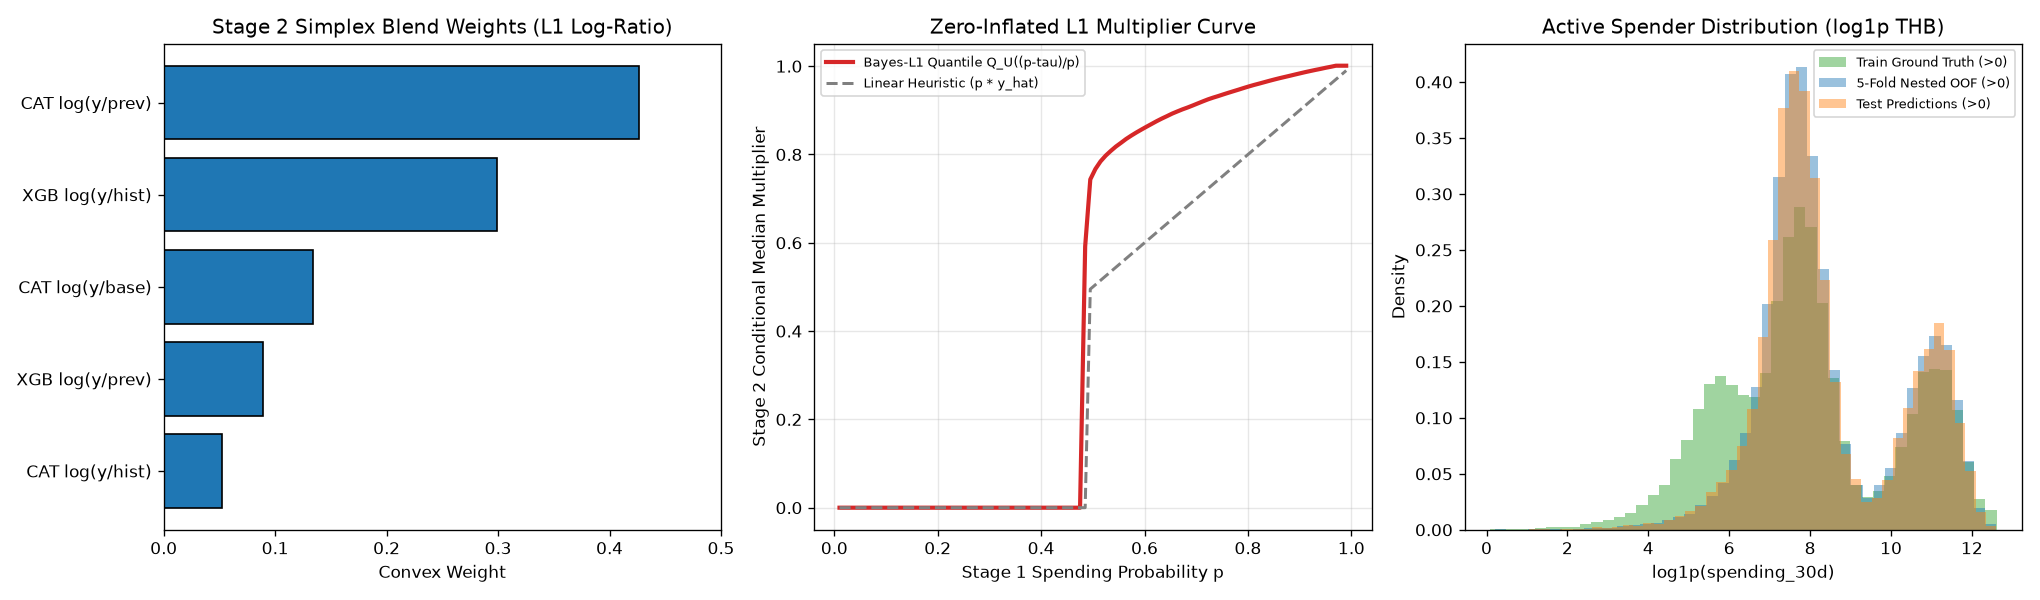

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

s2_labels = ["CAT log(y/prev)", "XGB log(y/hist)", "CAT log(y/base)", "XGB log(y/prev)", "CAT log(y/hist)"]
s2_weights = [0.426, 0.299, 0.134, 0.089, 0.052]
axes[0].barh(s2_labels[::-1], s2_weights[::-1], color="#1f77b4", edgecolor="black")
axes[0].set_title("Stage 2 Simplex Blend Weights (L1 Log-Ratio)")
axes[0].set_xlabel("Convex Weight")
axes[0].set_xlim(0, 0.50)

p_grid = np.linspace(0.01, 0.99, 100)
q_grid = np.clip((p_grid - avg_tau) / np.clip(p_grid, 1e-6, None), 0.0, 0.50)
c_curve = np.where(p_grid <= avg_tau, 0.0, np.quantile(u_all_sp, q_grid))
axes[1].plot(p_grid, c_curve, lw=2.5, color="#d62728", label="Bayes-L1 Quantile Q_U((p-tau)/p)")
axes[1].plot(p_grid, np.where(p_grid < 0.49, 0.0, p_grid), lw=1.8, ls="--", color="gray", label="Linear Heuristic (p * y_hat)")
axes[1].set_title("Zero-Inflated L1 Multiplier Curve")
axes[1].set_xlabel("Stage 1 Spending Probability p")
axes[1].set_ylabel("Stage 2 Conditional Median Multiplier")
axes[1].legend(loc="upper left", fontsize=8)
axes[1].grid(alpha=0.3)

axes[2].hist(np.log1p(y_all[y_all > 0]), bins=45, density=True, alpha=0.45, label="Train Ground Truth (>0)", color="#2ca02c")
axes[2].hist(np.log1p(oof_final_nested[oof_final_nested > 0]), bins=45, density=True, alpha=0.45, label="5-Fold Nested OOF (>0)", color="#1f77b4")
axes[2].hist(np.log1p(test_final_pred[test_final_pred > 0]), bins=45, density=True, alpha=0.45, label="Test Predictions (>0)", color="#ff7f0e")
axes[2].set_title("Active Spender Distribution (log1p THB)")
axes[2].set_xlabel("log1p(spending_30d)")
axes[2].set_ylabel("Density")
axes[2].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()
